<a href="https://colab.research.google.com/github/kevina29/MLA0202_Experiments/blob/main/MLA0202.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Training Dataset ---
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High  Strong  Cool   Change        Yes


Step 1 [Positive Instance]: ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']
Step 2 [Positive Instance]: ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
Step 3 [Negative Instance]: Ignored
Step 4 [Positive Instance]: ['Sunny', 'Warm', '?', 'Strong', '?', '?']

Most Specific Hypothesis found by FIND-S: ['Sunny', 'Warm', '?', 'Strong', '?', '?']



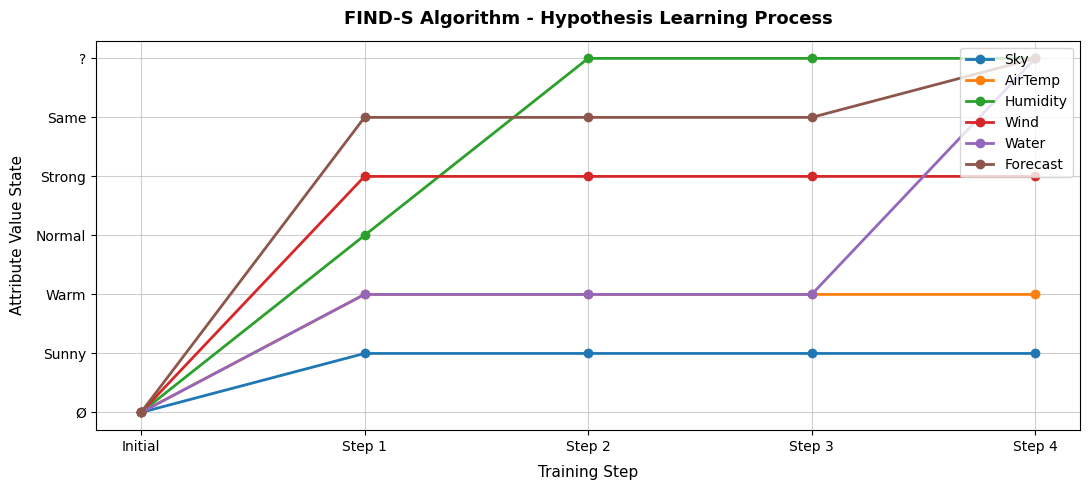

In [ ]:
import pandas as pd
import io
import matplotlib.pyplot as plt

# 1. Dataset Setup
csv_data = """Sky,AirTemp,Humidity,Wind,Water,Forecast,EnjoySport
Sunny,Warm,Normal,Strong,Warm,Same,Yes
Sunny,Warm,High,Strong,Warm,Same,Yes
Rainy,Cold,High,Strong,Warm,Change,No
Sunny,Warm,High,Strong,Cool,Change,Yes"""

df = pd.read_csv(io.StringIO(csv_data))
attributes = list(df.columns[:-1])

print("--- Training Dataset ---")
print(df)
print("\n" + "="*40 + "\n")

# 2. FIND-S Algorithm Execution & State History Tracking
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

# Initial most specific hypothesis
hypothesis = ['Ø'] * len(attributes)

# Steps: Initial, Step 1, Step 2, Step 3, Step 4
x_labels = ['Initial', 'Step 1', 'Step 2', 'Step 3', 'Step 4']
history = [list(hypothesis)]

# Process samples
for i, example in enumerate(X):
    if y[i] == 'Yes':
        if 'Ø' in hypothesis:
            hypothesis = list(example)
        else:
            for j in range(len(hypothesis)):
                if hypothesis[j] != example[j]:
                    hypothesis[j] = '?'
        print(f"Step {i+1} [Positive Instance]: {hypothesis}")
    else:
        print(f"Step {i+1} [Negative Instance]: Ignored")

    history.append(list(hypothesis))

print("\n" + "="*40)
print(f"Most Specific Hypothesis found by FIND-S: {hypothesis}\n")

# 3. Line Chart Trajectory Plot
# Order y-axis values logically so 'Ø' is at the bottom and '?' is at the top
y_order = ['Ø', 'Sunny', 'Warm', 'Normal', 'Strong', 'Same', '?']
val_to_y = {val: idx for idx, val in enumerate(y_order)}

plt.figure(figsize=(11, 5))

# Plot each attribute's state over the steps
for col_idx, attr_name in enumerate(attributes):
    attr_trajectory = [val_to_y[history[step][col_idx]] for step in range(len(history))]
    plt.plot(
        x_labels,
        attr_trajectory,
        marker='o',
        linewidth=2,
        label=attr_name
    )

plt.title('FIND-S Algorithm - Hypothesis Learning Process', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Training Step', fontsize=11, labelpad=8)
plt.ylabel('Attribute Value State', fontsize=11, labelpad=8)

# Set Y-axis ticks to match string values
plt.yticks(range(len(y_order)), y_order)

plt.grid(True, linestyle='-', alpha=0.6)
plt.legend(loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()

S0: ['Sunny', 'Warm', 'Normal', 'Strong']
G0: [['?', '?', '?', '?']]

Iteration 1: Example = ['Sunny', 'Warm', 'Normal', 'Strong'] | Label = yes
S_1: ['Sunny', 'Warm', 'Normal', 'Strong']
G_1: [['?', '?', '?', '?']]

Iteration 2: Example = ['Sunny', 'Warm', 'High', 'Strong'] | Label = yes
S_2: ['Sunny', 'Warm', '?', 'Strong']
G_2: [['?', '?', '?', '?']]

Iteration 3: Example = ['Rainy', 'Cold', 'High', 'Strong'] | Label = no
S_3: ['Sunny', 'Warm', '?', 'Strong']
G_3: [['Sunny', '?', '?', '?'], ['?', 'Warm', '?', '?']]

Iteration 4: Example = ['Sunny', 'Warm', 'High', 'Weak'] | Label = yes
S_4: ['Sunny', 'Warm', '?', '?']
G_4: [['Sunny', '?', '?', '?'], ['?', 'Warm', '?', '?']]



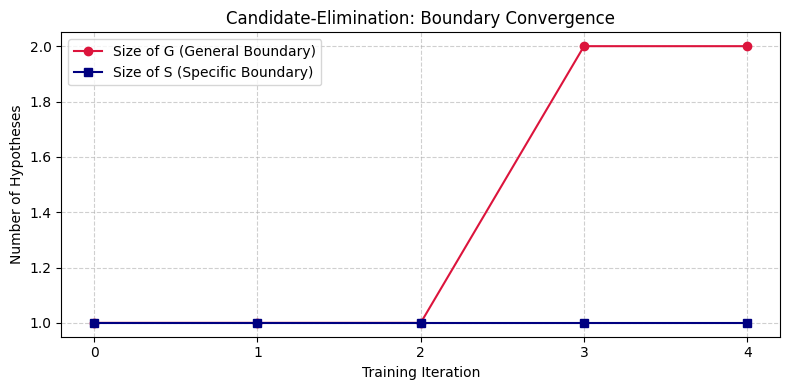

In [ ]:
import csv
import matplotlib.pyplot as plt

def candidate_elimination(filename):
    with open(filename, 'r') as file:
        reader = list(csv.reader(file))

    num_attributes = len(reader[0]) - 1

    # Initialize Specific (S) and General (G) boundaries
    S = ['0'] * num_attributes
    G = [['?' for _ in range(num_attributes)]]

    # Initialize S with the first positive example
    for row in reader[1:]:
        if row[-1].strip().lower() in ['yes', '1', 'true', 'enjoy']:
            S = row[:-1].copy()
            break

    # Track boundary sizes for visualization
    history_S = [S.copy()]
    history_G = [G.copy()]
    s_sizes = [1]
    g_sizes = [len(G)]

    print(f"S0: {S}")
    print(f"G0: {G}\n")

    for i, row in enumerate(reader[1:], start=1):
        attributes, target = row[:-1], row[-1].strip().lower()

        if target in ['yes', '1', 'true', 'enjoy']:  # Positive Example
            # Keep only hypotheses in G consistent with positive example
            G = [g for g in G if all(g[k] == '?' or g[k] == attributes[k] for k in range(num_attributes))]

            # Generalize S
            for k in range(num_attributes):
                if S[k] != attributes[k]:
                    S[k] = '?'

        else:  # Negative Example
            # Specialize G
            new_G = []
            for g in G:
                if all(g[k] == '?' or g[k] == attributes[k] for k in range(num_attributes)):
                    for k in range(num_attributes):
                        if g[k] == '?' and S[k] != attributes[k] and S[k] != '?':
                            g_new = g.copy()
                            g_new[k] = S[k]
                            if g_new not in new_G:
                                new_G.append(g_new)
                else:
                    if g not in new_G:
                        new_G.append(g)
            G = new_G

        s_sizes.append(1)
        g_sizes.append(len(G))
        history_S.append(S.copy())
        history_G.append(G.copy())

        print(f"Iteration {i}: Example = {attributes} | Label = {target}")
        print(f"S_{i}: {S}")
        print(f"G_{i}: {G}\n")

    plot_convergence(g_sizes, s_sizes)
    return S, G

def plot_convergence(g_sizes, s_sizes):
    plt.figure(figsize=(8, 4))
    plt.plot(range(len(g_sizes)), g_sizes, marker='o', color='crimson', label='Size of G (General Boundary)')
    plt.plot(range(len(s_sizes)), s_sizes, marker='s', color='navy', label='Size of S (Specific Boundary)')
    plt.title('Candidate-Elimination: Boundary Convergence')
    plt.xlabel('Training Iteration')
    plt.ylabel('Number of Hypotheses')
    plt.xticks(range(len(g_sizes)))
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()

# --- Create sample dataset CSV and execute ---
csv_content = """Outlook,Temperature,Humidity,Wind,EnjoySport
Sunny,Warm,Normal,Strong,Yes
Sunny,Warm,High,Strong,Yes
Rainy,Cold,High,Strong,No
Sunny,Warm,High,Weak,Yes"""

with open("training_data.csv", "w") as f:
    f.write(csv_content)

final_S, final_G = candidate_elimination("training_data.csv")

New Sample: {'Outlook': 'Sunny', 'Temperature': 'Cool', 'Humidity': 'High', 'Wind': 'Strong'}
Predicted Class: Yes


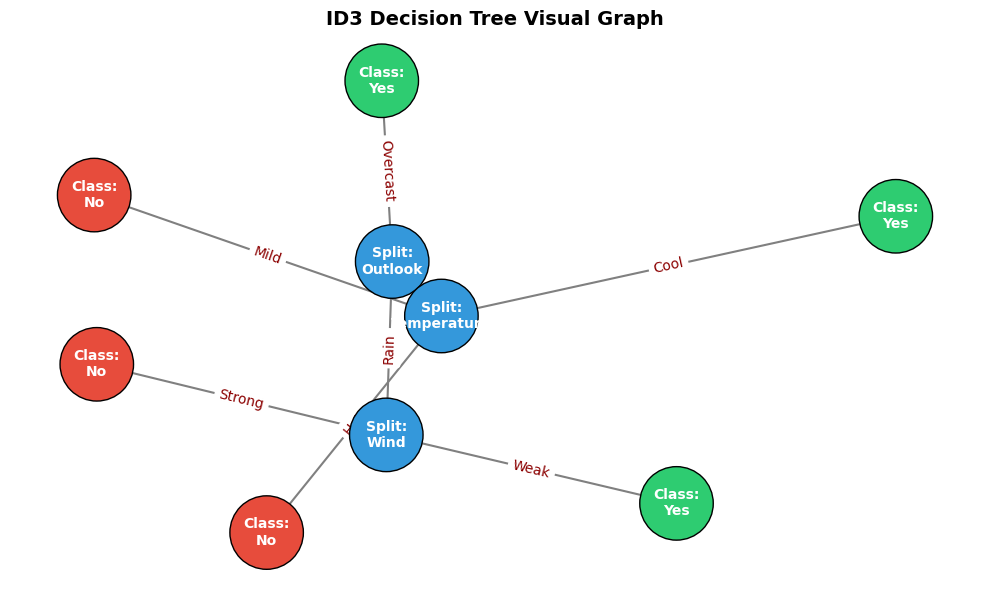

In [ ]:
import math
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

class Node:
    def __init__(self, attribute=None, value=None, results=None):
        self.attribute = attribute  # Feature to split on
        self.value = value          # Feature value leading to this node
        self.results = results      # Leaf class label
        self.children = {}

def entropy(data, target_col):
    values = data[target_col].value_counts()
    ent = 0.0
    for val in values:
        p = val / len(data)
        ent -= p * math.log2(p)
    return ent

def information_gain(data, split_attribute, target_col):
    total_entropy = entropy(data, target_col)
    values = data[split_attribute].value_counts()
    weighted_entropy = 0.0
    for val, count in values.items():
        subset = data[data[split_attribute] == val]
        weighted_entropy += (count / len(data)) * entropy(subset, target_col)
    return total_entropy - weighted_entropy

def id3(data, target_col, features):
    labels = data[target_col].unique()

    if len(labels) == 1:
        return Node(results=labels[0])
    if not features:
        return Node(results=data[target_col].mode()[0])

    gains = {feat: information_gain(data, feat, target_col) for feat in features}
    best_feature = max(gains, key=gains.get)

    root = Node(attribute=best_feature)
    remaining_features = [f for f in features if f != best_feature]

    for val in data[best_feature].unique():
        subset = data[data[best_feature] == val]
        child_node = id3(subset, target_col, remaining_features)
        child_node.value = val
        root.children[val] = child_node

    return root

def classify(tree, sample):
    if tree.results is not None:
        return tree.results
    attr_val = sample.get(tree.attribute)
    if attr_val in tree.children:
        return classify(tree.children[attr_val], sample)
    return None

def plot_decision_tree(root):
    G = nx.DiGraph()
    node_labels = {}
    edge_labels = {}
    node_colors = []
    node_id = [0]

    def add_nodes_edges(node, parent_id=None, edge_text=""):
        current_id = node_id[0]
        node_id[0] += 1

        if node.results is not None:
            node_labels[current_id] = f"Class:\n{node.results}"
            G.add_node(current_id)
            node_colors.append('#2ecc71' if str(node.results).lower() in ['yes', '1'] else '#e74c3c')
        else:
            node_labels[current_id] = f"Split:\n{node.attribute}"
            G.add_node(current_id)
            node_colors.append('#3498db')

        if parent_id is not None:
            G.add_edge(parent_id, current_id)
            edge_labels[(parent_id, current_id)] = edge_text

        for val, child in node.children.items():
            add_nodes_edges(child, current_id, str(val))

    add_nodes_edges(root)

    plt.figure(figsize=(10, 6))
    pos = nx.spring_layout(G, seed=42)
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=2800, edgecolors='black')
    nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=15, edge_color='gray', width=1.5)
    nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=10, font_weight='bold', font_color='white')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='darkred', font_size=10)

    plt.title("ID3 Decision Tree Visual Graph", fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

# --- Sample Dataset and Execution ---
data = pd.DataFrame({
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain', 'Rain', 'Overcast', 'Sunny', 'Sunny', 'Rain'],
    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool', 'Cool', 'Cool', 'Mild', 'Cool', 'Mild'],
    'Humidity': ['High', 'High', 'High', 'High', 'Normal', 'Normal', 'Normal', 'High', 'Normal', 'Normal'],
    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 'Weak', 'Weak', 'Weak'],
    'PlayTennis': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes']
})

features = list(data.columns[:-1])
tree = id3(data, 'PlayTennis', features)

# Classify a new sample
new_sample = {'Outlook': 'Sunny', 'Temperature': 'Cool', 'Humidity': 'High', 'Wind': 'Strong'}
prediction = classify(tree, new_sample)

print(f"New Sample: {new_sample}")
print(f"Predicted Class: {prediction}")

# Render Decision Tree Graph
plot_decision_tree(tree)

Backpropagation Neural Network Predictions:
Input: [0 0] | Target: 0 | Predicted Output: 0.0163 (Rounded: 0)
Input: [0 1] | Target: 1 | Predicted Output: 0.9889 (Rounded: 1)
Input: [1 0] | Target: 1 | Predicted Output: 0.9758 (Rounded: 1)
Input: [1 1] | Target: 0 | Predicted Output: 0.0214 (Rounded: 0)


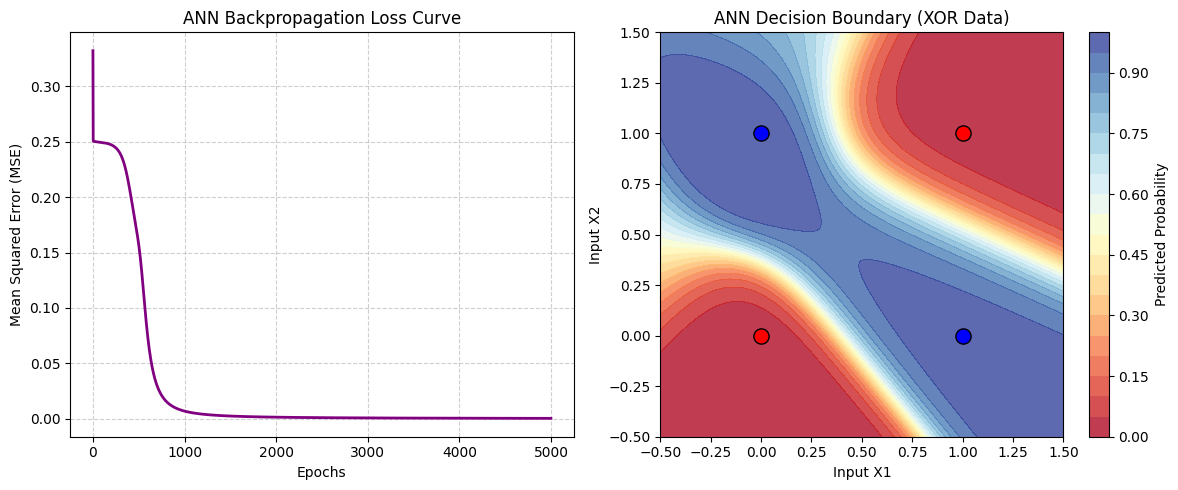

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1.0 - x)

class NeuralNetwork:
    def __init__(self, input_size, hidden_size, output_size, lr=0.8):
        self.lr = lr
        np.random.seed(42)
        self.W1 = np.random.uniform(size=(input_size, hidden_size))
        self.b1 = np.random.uniform(size=(1, hidden_size))
        self.W2 = np.random.uniform(size=(hidden_size, output_size))
        self.b2 = np.random.uniform(size=(1, output_size))
        self.losses = []

    def forward(self, X):
        self.hidden_input = np.dot(X, self.W1) + self.b1
        self.hidden_output = sigmoid(self.hidden_input)
        self.final_input = np.dot(self.hidden_output, self.W2) + self.b2
        self.final_output = sigmoid(self.final_input)
        return self.final_output

    def backward(self, X, y, output):
        error_output = y - output
        loss = np.mean(error_output ** 2)
        self.losses.append(loss)

        # Gradients
        d_output = error_output * sigmoid_derivative(output)
        error_hidden = d_output.dot(self.W2.T)
        d_hidden = error_hidden * sigmoid_derivative(self.hidden_output)

        # Weight and bias updates
        self.W2 += self.hidden_output.T.dot(d_output) * self.lr
        self.b2 += np.sum(d_output, axis=0, keepdims=True) * self.lr
        self.W1 += X.T.dot(d_hidden) * self.lr
        self.b1 += np.sum(d_hidden, axis=0, keepdims=True) * self.lr

    def train(self, X, y, epochs=5000):
        for _ in range(epochs):
            output = self.forward(X)
            self.backward(X, y, output)

def plot_ann_results(nn, X, y):
    plt.figure(figsize=(12, 5))

    # Plot 1: Loss Curve
    plt.subplot(1, 2, 1)
    plt.plot(nn.losses, color='purple', linewidth=2)
    plt.title("ANN Backpropagation Loss Curve")
    plt.xlabel("Epochs")
    plt.ylabel("Mean Squared Error (MSE)")
    plt.grid(True, linestyle='--', alpha=0.6)

    # Plot 2: Decision Boundary Contour Plot
    plt.subplot(1, 2, 2)
    x_min, x_max = -0.5, 1.5
    y_min, y_max = -0.5, 1.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = nn.forward(grid)
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, levels=20, cmap='RdYlBu', alpha=0.8)
    plt.colorbar(label='Predicted Probability')

    for i in range(len(X)):
        color = 'blue' if y[i][0] == 1 else 'red'
        plt.scatter(X[i, 0], X[i, 1], c=color, edgecolors='black', s=120, zorder=5)

    plt.title("ANN Decision Boundary (XOR Data)")
    plt.xlabel("Input X1")
    plt.ylabel("Input X2")
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)

    plt.tight_layout()
    plt.show()

# --- Dataset: Non-linearly Separable XOR Logic ---
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])

nn = NeuralNetwork(input_size=2, hidden_size=4, output_size=1, lr=0.8)
nn.train(X, y, epochs=5000)

print("Backpropagation Neural Network Predictions:")
for i in range(len(X)):
    pred = nn.forward(X[i:i+1])[0][0]
    print(f"Input: {X[i]} | Target: {y[i][0]} | Predicted Output: {pred:.4f} (Rounded: {round(pred)})")

plot_ann_results(nn, X, y)